# Time-lapse tomography: keep the covariance

**Question.** After mapping phase-velocity changes laterally, what uncertainty must you propagate into a depth inversion?

This is a **synthetic four-cell acquisition experiment**, using the volcano column from Tutorial 2. We compare a joint path–depth linear inversion with a two-stage phase-map → depth inversion. For this linear Gaussian example, both should agree when the full phase-map covariance is retained. Discarding lateral covariance loses that equivalence.

The ray calculation is teaching code, separate from the GESC modal solver. It is not a production tomography backend: no ray bending, topography, finite-frequency kernels, attenuation, or noise-correlation processing. [Bensen et al. (2007)](https://doi.org/10.1111/j.1365-246X.2007.03374.x) provide context for dispersion measurements and QC before such an inversion.


In [1]:
import sys
from pathlib import Path

# Run from the repository root or its tutorials/ directory.
root = Path.cwd().resolve()
if root.name == "tutorials":
    root = root.parent
if not (root / "src" / "gesc").is_dir():
    raise RuntimeError("Run this notebook from the gesc-python checkout.")
sys.path.insert(0, str(root))
sys.path.insert(0, str(root / "src"))
import matplotlib.pyplot as plt
import numpy as np

from gesc import solve_modes
from gesc.sensitivity import linearize_phase
from tutorials.plotting import emit_metrics, style
from tutorials.scenarios import phase_observation

style()
np.set_printoptions(precision=5, suppress=True)
%matplotlib inline

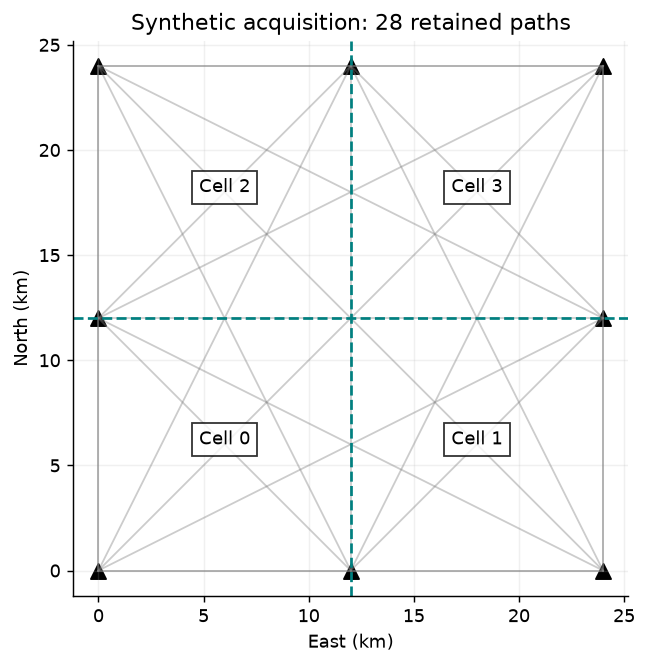

In [2]:
from itertools import combinations

from scipy.linalg import block_diag

from tutorials.scenarios import volcano
from tutorials.tomography import gaussian_condition, path_lengths

model, request = volcano()
modes = solve_modes(model, request).fundamental()
operator = linearize_phase(model, request, phase_observation(request))
G = np.array(operator.g)
f = np.array(request.frequencies_hz)
c0 = np.array([m.phase_velocity_m_s for m in modes])
# Four 12 km x 12 km cells, eight perimeter stations.
edges = np.array([0.0, 12000.0, 24000.0])
stations = np.array(
    [
        (0, 0),
        (12000, 0),
        (24000, 0),
        (24000, 12000),
        (24000, 24000),
        (12000, 24000),
        (0, 24000),
        (0, 12000),
    ],
    dtype=float,
)
pairs = list(combinations(range(len(stations)), 2))
L = np.array([path_lengths(stations[i], stations[j], edges, edges) for i, j in pairs])
# Conservative illustrative aperture screen; not a universal measurement rule.
keep = L.sum(axis=1) >= 3 * np.max(c0 / f)
pairs = [pair for pair, selected in zip(pairs, keep, strict=True) if selected]
L = L[keep]
assert np.linalg.matrix_rank(L) == 4
assert np.allclose(L.sum(axis=1), [np.linalg.norm(stations[j] - stations[i]) for i, j in pairs])
fig, ax = plt.subplots(figsize=(5.5, 5))
for i, j in pairs:
    ax.plot(stations[[i, j], 0] / 1000, stations[[i, j], 1] / 1000, color="gray", alpha=0.4, lw=1)
ax.scatter(stations[:, 0] / 1000, stations[:, 1] / 1000, marker="^", s=70, color="black")
ax.axvline(12, color="teal", ls="--")
ax.axhline(12, color="teal", ls="--")
for cell, (x, y) in enumerate(((6, 6), (18, 6), (6, 18), (18, 18))):
    ax.text(x, y, f"Cell {cell}", ha="center", bbox=dict(facecolor="white", alpha=0.8))
ax.set(
    xlabel="East (km)",
    ylabel="North (km)",
    title=f"Synthetic acquisition: {len(pairs)} retained paths",
    aspect="equal",
)
plt.show()

## 1. Compose lateral and depth sensitivity

For a small fractional phase change $d_{jf}$ in lateral cell $j$,
$$\Delta t_{pf}\simeq-\sum_j\frac{L_{pj}}{c_0(f)}d_{jf},\qquad d_{jf}=\sum_iG_{fi}a_{ji}.$$

We use **phase travel-time changes at each frequency**, not group arrival times or coda stretching. The background is laterally uniform and rays stay fixed. Build a frequency-major path matrix $K$ with cell-major depth coefficients. Even dense ray coverage does not eliminate the approximation that wavelengths and Fresnel zones have finite width.


In [3]:
depth_truth = np.array([[-0.0015, 0, 0], [0, -0.001, 0], [0, 0, 0], [-0.0005, -0.0005, 0]])
ray_designs = [-L / speed for speed in c0]
K = np.vstack(
    [(B[:, :, None] * G[fi][None, None, :]).reshape(len(L), 12) for fi, B in enumerate(ray_designs)]
)
sigma_t = 0.01  # chosen 10 ms uncertainty in each synthetic phase-time change
Cd = np.eye(K.shape[0]) * sigma_t**2
Ca = np.eye(12) * 0.002**2
rng = np.random.default_rng(247)
true_delay = K @ depth_truth.ravel()
observed_delay = true_delay + rng.normal(0, sigma_t, K.shape[0])
joint_mean, joint_cov, joint_averaging = gaussian_condition(K, observed_delay, Cd, Ca)
print("Design shape (paths x frequencies, regional coefficients):", K.shape)
print("Longest wavelength (km):", np.max(c0 / f) / 1000)
print("Retained minimum path length (km):", np.min(L.sum(axis=1)) / 1000)

Design shape (paths x frequencies, regional coefficients): (168, 12)
Longest wavelength (km): 3.8911705053569285
Retained minimum path length (km): 12.0


## 2. Make phase maps without discarding map covariance

Each frequency map is an unregularized least-squares estimate in this full-rank toy geometry. Its covariance is generally **not diagonal across cells**. The likelihood-preserving transform allows the full two-stage result to match the joint result. For regularized maps, the averaging/transfer operator and bias must also be propagated; treating a smoothed map as independent raw data is insufficient.


In [4]:
phase_maps, map_covariances = [], []
for fi, B in enumerate(ray_designs):
    left_inverse = np.linalg.solve(B.T @ B, B.T)
    block = observed_delay[fi * len(L) : (fi + 1) * len(L)]
    phase_maps.append(left_inverse @ block)
    map_covariances.append(sigma_t**2 * left_inverse @ left_inverse.T)
phase_maps = np.array(phase_maps)
map_covariance = block_diag(*map_covariances)
D = np.vstack([np.kron(np.eye(4), G[fi : fi + 1]) for fi in range(len(f))])
staged_mean, staged_cov, staged_averaging = gaussian_condition(
    D, phase_maps.ravel(), map_covariance, Ca
)
np.testing.assert_allclose(joint_mean, staged_mean, rtol=1e-7, atol=1e-10)
np.testing.assert_allclose(joint_cov, staged_cov, rtol=1e-7, atol=1e-12)
wrong_mean, wrong_cov, _ = gaussian_condition(
    D, phase_maps.ravel(), np.diag(np.diag(map_covariance)), Ca
)
assert not np.allclose(joint_cov, wrong_cov, rtol=1e-4, atol=1e-12)
print(
    "Joint vs two-stage maximum coefficient difference:", np.max(np.abs(joint_mean - staged_mean))
)
print(
    "Posterior SD ratio after discarding covariance:",
    np.sqrt(np.diag(wrong_cov) / np.diag(joint_cov)),
)

Joint vs two-stage maximum coefficient difference: 1.1194387430912833e-17
Posterior SD ratio after discarding covariance: [1.00042 1.0022  1.00821 1.00053 1.0028  1.01044 1.00053 1.0028  1.01044
 1.00064 1.00344 1.01281]


## 3. Separate lateral coverage from depth resolution

Look at the imposed and inferred maps in each depth interval. Then inspect the full averaging matrix: lateral leakage and depth leakage are different limitations, and both can occur even with a good fit to phase delays.


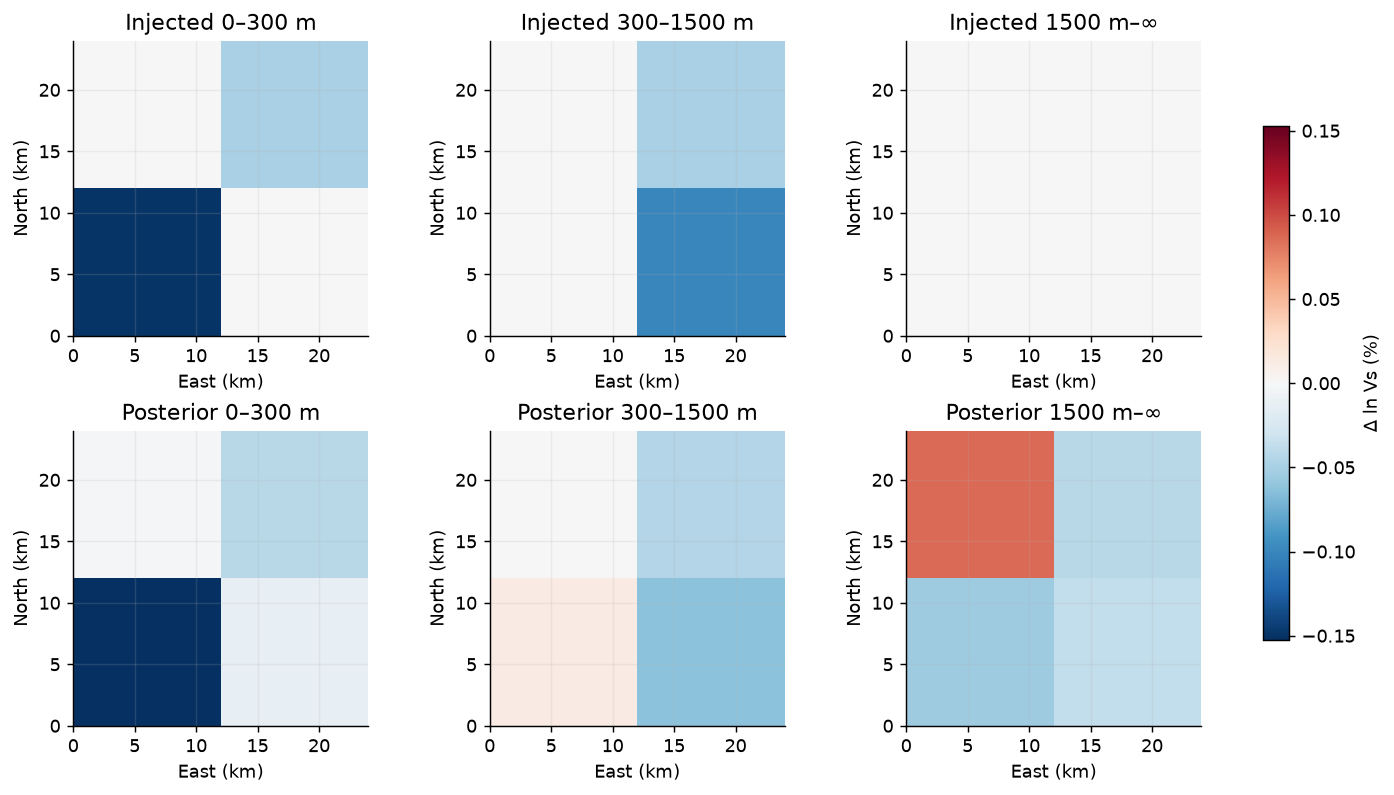

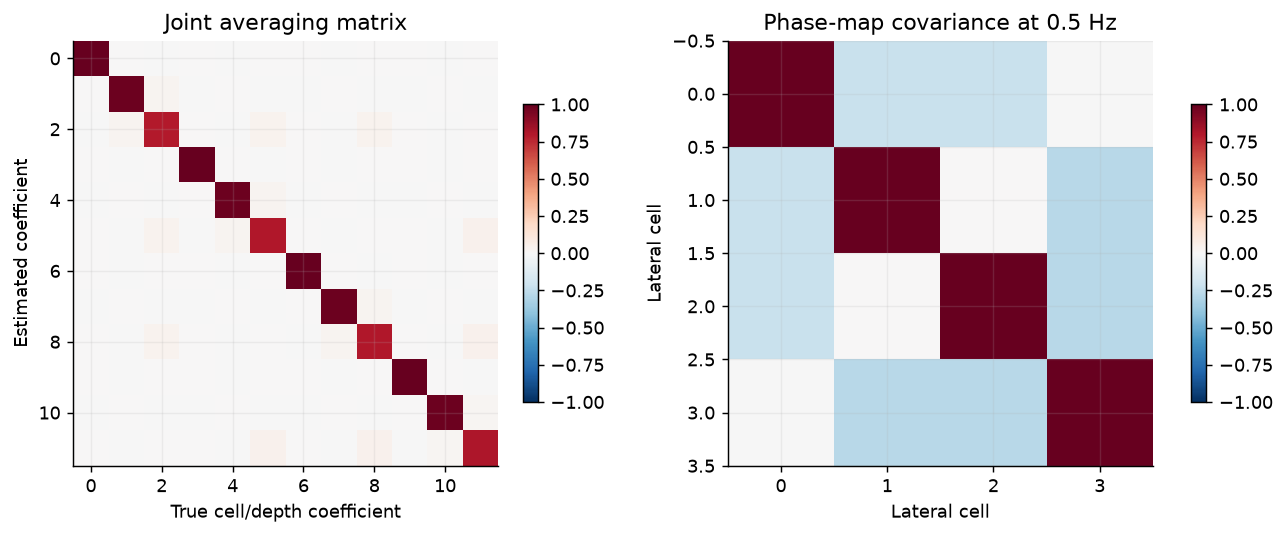

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
limit = max(np.max(np.abs(depth_truth)), np.max(np.abs(joint_mean))) * 100
for j, label in enumerate(("0–300 m", "300–1500 m", "1500 m–∞")):
    for row, values in enumerate((depth_truth, joint_mean.reshape(4, 3))):
        image = axes[row, j].imshow(
            values[:, j].reshape(2, 2) * 100,
            origin="lower",
            extent=(0, 24, 0, 24),
            cmap="RdBu_r",
            vmin=-limit,
            vmax=limit,
        )
        axes[row, j].set(
            title=("Injected " if row == 0 else "Posterior ") + label,
            xlabel="East (km)",
            ylabel="North (km)",
        )
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.75, label="Δ ln Vs (%)")
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
image = axes[0].imshow(joint_averaging, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set(
    xlabel="True cell/depth coefficient",
    ylabel="Estimated coefficient",
    title="Joint averaging matrix",
)
fig.colorbar(image, ax=axes[0], shrink=0.7)
sd_map = np.sqrt(np.diag(map_covariances[0]))
corr_map = map_covariances[0] / np.outer(sd_map, sd_map)
image = axes[1].imshow(corr_map, cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set(
    xlabel="Lateral cell", ylabel="Lateral cell", title=f"Phase-map covariance at {f[0]:g} Hz"
)
fig.colorbar(image, ax=axes[1], shrink=0.7)
plt.show()

## What changes for a real volcano array?

Use measured phase-dispersion uncertainties, realistic geometry, background-dependent paths or finite-frequency kernels, and a spatial prior supported by the survey. Carry cross-frequency and lateral covariance. Recompute the depth operator for distinct local background models. GESC supplies the local modal/depth response; acquisition processing and lateral tomography remain separate components.

**Try:** remove stations on one side, restrict the low-frequency aperture, or compare the full covariance with its diagonal. The equivalence demonstrated here is conditional on a linear model, full-rank unsmoothed phase maps, and consistent priors.


In [6]:
emit_metrics(
    {
        "case": "synthetic four-cell time-lapse tomography",
        "retained_paths": len(L),
        "max_joint_staged_difference": float(np.max(np.abs(joint_mean - staged_mean))),
        "max_sd_ratio_without_map_covariance": float(
            np.max(np.sqrt(np.diag(wrong_cov) / np.diag(joint_cov)))
        ),
        "checks_passed": True,
    }
)

{
  "case": "synthetic four-cell time-lapse tomography",
  "retained_paths": 28,
  "max_joint_staged_difference": 1.1194387430912833e-17,
  "max_sd_ratio_without_map_covariance": 1.0128129779836759,
  "checks_passed": true
}

case,synthetic four-cell time-lapse tomography
retained paths,28
max joint staged difference,1.1194387430912833e-17
max sd ratio without map covariance,1.0128129779836759
checks passed,True
